In [ ]:
from google.colab import files
uploaded = files.upload()

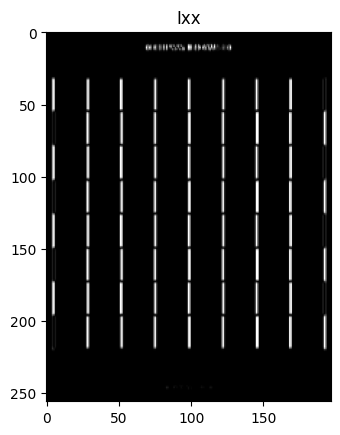

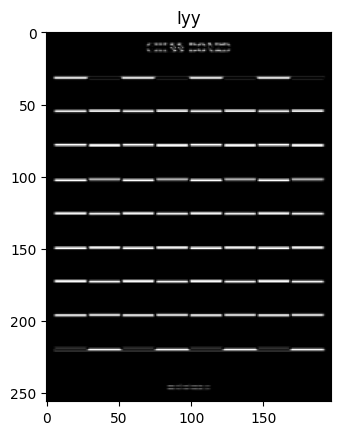

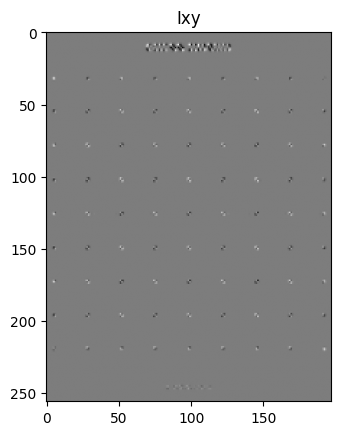

In [ ]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

img = cv2.imread("chessboard  köşe tespiti  (2).png")
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
gray = gray.astype(np.float32)

Ix = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3)
Iy = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=3)

Ixx = Ix * Ix
Iyy = Iy * Iy
Ixy = Ix * Iy

plt.imshow(Ixx, cmap='gray')
plt.title('Ixx')
plt.show()
plt.imshow(Iyy, cmap='gray')
plt.title('Iyy')
plt.show()
plt.imshow(Ixy, cmap='gray')
plt.title('Ixy')
plt.show()

In [ ]:
window_size = 5
Sxx = cv2.boxFilter(Ixx, ddepth=-1, ksize=(window_size, window_size))
Syy = cv2.boxFilter(Iyy, ddepth=-1, ksize=(window_size, window_size))
Sxy = cv2.boxFilter(Ixy, ddepth=-1, ksize=(window_size, window_size))

trace = Sxx + Syy
det_term = np.sqrt(((Sxx - Syy) / 2) ** 2 + Sxy ** 2)

lambda1 = trace / 2 + det_term
lambda2 = trace / 2 - det_term

print(lambda1.min(), lambda1.max())
print(lambda2.min(), lambda2.max())
threshold_ratio = 0.01
threshold = threshold_ratio * lambda2.max()

corners_mask = lambda2 > threshold
print(corners_mask.sum())

0.0 433269.02080917585
0.0 274094.9181015572
4248


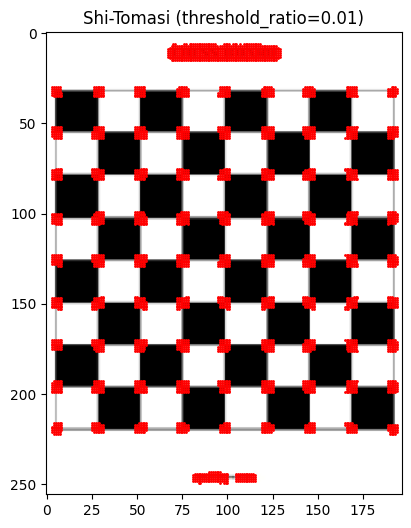

In [ ]:
img_color = cv2.imread("chessboard  köşe tespiti  (2).png")
ys, xs = np.where(corners_mask)

plt.figure(figsize=(6,6))
plt.imshow(cv2.cvtColor(img_color, cv2.COLOR_BGR2RGB))
plt.scatter(xs, ys, s=1, c='red')
plt.title(f'Shi-Tomasi (threshold_ratio={threshold_ratio})')
plt.show()

95


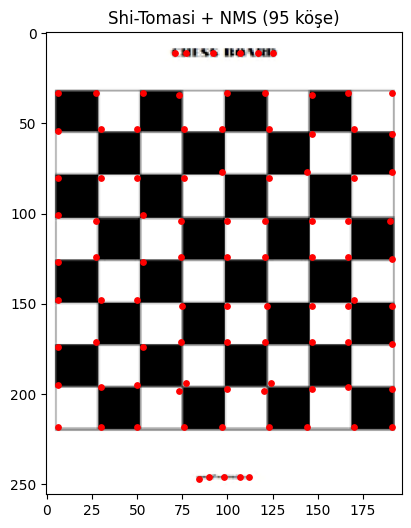

<Figure size 640x480 with 0 Axes>

In [ ]:
from scipy.ndimage import maximum_filter
local_max = maximum_filter(lambda2, size=7)
is_local_max = (lambda2 == local_max)
corners_nms = corners_mask & is_local_max
print(corners_nms.sum())
ys, xs = np.where(corners_nms)

plt.figure(figsize=(6,6))
plt.imshow(cv2.cvtColor(img_color, cv2.COLOR_BGR2RGB))
plt.scatter(xs, ys, s=15, c='red',marker='o')
plt.title(f'Shi-Tomasi + NMS (95 köşe)')
plt.show()
plt.savefig('shi_tomasi_checkerboard.png', bbox_inches='tight')
